In [2]:
import numpy as np
import pandas as pd
import os


In [3]:
from src.defects import (
    make_entity_inconsistency_plan,
    inject_entity_inconsistency
)

In [4]:
clean_campaigns = pd.read_csv(
    "../data/processed/clean_structured_campaigns.csv",
    parse_dates=["timestamp"]
)

print(
    "Number of campaigns:",
    clean_campaigns["campaign_id"].nunique()
)

print(
    "Number of messages:",
    len(clean_campaigns)
)

print(
    "Average messages per campaign:",
    clean_campaigns.groupby(
        "campaign_id"
    ).size().mean()
)

display(
    clean_campaigns.head(10)
)

Number of campaigns: 1000
Number of messages: 6949
Average messages per campaign: 6.949


,campaign_id,message_id,message_order,timestamp,channel,sender,recipient,text,entity_id,reference_id,parent_message_id
0,C0001,C0001_M01,1,2026-03-18 13:19:00,whatsapp,advisor_20,client_0001,"Hi Daniel Vega, here is the summary for your r...",E0001,NaN,NaN
1,C0001,C0001_M02,2,2026-03-18 15:14:00,whatsapp,client_0001,advisor_20,"Thanks, I received the information.",E0001,NaN,C0001_M01
2,C0001,C0001_M03,3,2026-03-18 16:49:00,email,advisor_20,client_0001,Following up here on the whatsapp message I se...,E0001,C0001_M01,C0001_M02
3,C0001,C0001_M04,4,2026-03-18 17:53:00,whatsapp,client_0001,advisor_20,I reviewed the information and I have a questi...,E0001,NaN,C0001_M03
4,C0001,C0001_M05,5,2026-03-18 19:46:00,whatsapp,advisor_20,client_0001,"Certainly, Daniel Vega. I will explain that in...",E0001,NaN,C0001_M04
5,C0001,C0001_M06,6,2026-03-18 20:41:00,email,client_0001,advisor_20,That makes sense. Thank you.,E0001,NaN,C0001_M05
6,C0001,C0001_M07,7,2026-03-18 21:02:00,whatsapp,advisor_20,client_0001,Let me know if you need any additional informa...,E0001,NaN,C0001_M06
7,C0002,C0002_M01,1,2026-06-03 09:38:00,whatsapp,advisor_01,client_0002,"Hello Thomas Foster, I am sharing the initial ...",E0002,NaN,NaN
8,C0002,C0002_M02,2,2026-06-03 10:27:00,email,client_0002,advisor_01,Thank you. I will review it.,E0002,NaN,C0002_M01
9,C0002,C0002_M03,3,2026-06-03 12:02:00,sms,advisor_01,client_0002,Following up here on the whatsapp message I se...,E0002,C0002_M01,C0002_M02


In [5]:
entity_catalog = pd.read_csv(
    "../data/processed/entity_catalog.csv"
)

print(
    "Entities:",
    len(entity_catalog)
)

display(
    entity_catalog.head()
)

Entities: 1000


,entity_id,canonical_name,client_id
0,E0001,Daniel Vega,client_0001
1,E0002,Thomas Foster,client_0002
2,E0003,Julia Collins,client_0003
3,E0004,Olivia Bailey,client_0004
4,E0005,Sara Castro,client_0005


In [6]:
split_df = pd.read_csv(
    "../data/processed/structural_campaign_split.csv"
)

print(
    split_df["split"].value_counts()
)

display(
    split_df.head()
)

split
train         700
evaluation    300
Name: count, dtype: int64


,campaign_id,split
0,C0001,train
1,C0002,train
2,C0003,evaluation
3,C0004,evaluation
4,C0005,train


In [7]:
train_ids = set(
    split_df.loc[
        split_df["split"] == "train",
        "campaign_id"
    ]
)

eval_ids = set(
    split_df.loc[
        split_df["split"] == "evaluation",
        "campaign_id"
    ]
)

print(
    "Training/reference campaigns:",
    len(train_ids)
)

print(
    "Evaluation campaigns:",
    len(eval_ids)
)

print(
    "Overlap:",
    len(train_ids & eval_ids)
)

assert len(train_ids) == 700
assert len(eval_ids) == 300
assert train_ids.isdisjoint(eval_ids)

Training/reference campaigns: 700
Evaluation campaigns: 300
Overlap: 0


In [8]:
clean_campaigns_eval = (
    clean_campaigns[
        clean_campaigns["campaign_id"]
        .isin(eval_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Evaluation campaigns:",
    clean_campaigns_eval[
        "campaign_id"
    ].nunique()
)

print(
    "Evaluation messages:",
    len(clean_campaigns_eval)
)

display(
    clean_campaigns_eval.head()
)

Evaluation campaigns: 300
Evaluation messages: 2090


,campaign_id,message_id,message_order,timestamp,channel,sender,recipient,text,entity_id,reference_id,parent_message_id
0,C0003,C0003_M01,1,2026-02-19 12:01:00,sms,advisor_07,client_0003,"Hi Julia Collins, here is the summary for your...",E0003,NaN,NaN
1,C0003,C0003_M02,2,2026-02-19 12:44:00,sms,client_0003,advisor_07,"I received it, thanks. I will take a look.",E0003,NaN,C0003_M01
2,C0003,C0003_M03,3,2026-02-19 13:36:00,email,advisor_07,client_0003,Following up here on the sms message I sent ea...,E0003,C0003_M01,C0003_M02
3,C0003,C0003_M04,4,2026-02-19 14:31:00,email,client_0003,advisor_07,I reviewed the information and I have a questi...,E0003,NaN,C0003_M03
4,C0003,C0003_M05,5,2026-02-19 15:39:00,email,advisor_07,client_0003,"Of course, Julia Collins. I can clarify that p...",E0003,NaN,C0003_M04


In [9]:
entity_inconsistency_plan = (
    make_entity_inconsistency_plan(
        clean_campaigns_eval,
        entity_catalog,
        seed=42
    )
)

In [10]:
print(
    "Campaigns in plan:",
    len(entity_inconsistency_plan)
)

display(
    entity_inconsistency_plan.head()
)

Campaigns in plan: 300


,campaign_id,entity_id,target_message_id,target_message_order,canonical_name,inconsistent_name,severity_rank
0,C0003,E0003,C0003_M03,3,Julia Collins,Julia Rivera,244
1,C0004,E0004,C0004_M05,5,Olivia Bailey,Olivia Medina,107
2,C0006,E0006,C0006_M05,5,Valeria Silva,Valeria Santos,190
3,C0008,E0008,C0008_M03,3,Martin Lopez,Martin Ramos,228
4,C0010,E0010,C0010_M03,3,Paula Gray,Paula Campos,48


In [11]:
ENTITY_SEVERITIES = [
    0.10,
    0.30,
    0.60
]

entity_inconsistency_results = {}

for severity in ENTITY_SEVERITIES:

    defective_s, audit_s = (
        inject_entity_inconsistency(
            clean_campaigns_eval,
            entity_inconsistency_plan,
            severity=severity
        )
    )

    entity_inconsistency_results[
        severity
    ] = {
        "defective": defective_s,
        "audit": audit_s
    }

    print(
        f"Severity {severity:.0%} | "
        f"Affected campaigns: "
        f"{len(audit_s)}"
    )

Severity 10% | Affected campaigns: 30
Severity 30% | Affected campaigns: 90
Severity 60% | Affected campaigns: 180


In [12]:
ids_10 = set(
    entity_inconsistency_results[
        0.10
    ]["audit"]["campaign_id"]
)

ids_30 = set(
    entity_inconsistency_results[
        0.30
    ]["audit"]["campaign_id"]
)

ids_60 = set(
    entity_inconsistency_results[
        0.60
    ]["audit"]["campaign_id"]
)

assert ids_10.issubset(
    ids_30
)

assert ids_30.issubset(
    ids_60
)

print(
    "Nested severity validation passed."
)

print(
    len(ids_10),
    len(ids_30),
    len(ids_60)
)

Nested severity validation passed.
30 90 180


In [13]:
NON_TEXT_COLUMNS = [
    "campaign_id",
    "message_id",
    "message_order",
    "timestamp",
    "channel",
    "sender",
    "recipient",
    "entity_id",
    "reference_id",
    "parent_message_id"
]

for severity in ENTITY_SEVERITIES:

    defective = (
        entity_inconsistency_results[
            severity
        ]["defective"]
    )

    assert (
        clean_campaigns_eval[
            NON_TEXT_COLUMNS
        ]
        .reset_index(drop=True)
        .equals(
            defective[
                NON_TEXT_COLUMNS
            ]
            .reset_index(drop=True)
        )
    )

print(
    "All non-text fields were preserved."
)

All non-text fields were preserved.


In [14]:
# inspect examples
display(
    entity_inconsistency_results[
        0.10
    ]["audit"][
        [
            "campaign_id",
            "target_message_order",
            "canonical_name",
            "inconsistent_name",
            "original_text",
            "defective_text"
        ]
    ].head(10)
)

,campaign_id,target_message_order,canonical_name,inconsistent_name,original_text,defective_text
0,C0034,3,Olivia Mendoza,Olivia Turner,Following up here on the sms message I sent ea...,Following up here on the sms message I sent ea...
1,C0073,7,Daniel Ramos,Daniel Ruiz,Feel free to contact me if anything else comes...,Feel free to contact me if anything else comes...
2,C0079,5,Eric Ramos,Eric Bennett,"Certainly, Eric Ramos. I will explain that in ...","Certainly, Eric Bennett. I will explain that i..."
3,C0083,7,Carlos Castro,Carlos Ramos,"I can provide more information if needed, Carl...","I can provide more information if needed, Carl..."
4,C0085,9,Sara Morris,Sara Rivera,"I can provide more information if needed, Sara...","I can provide more information if needed, Sara..."
5,C0119,5,Daniel Rivera,Daniel Parker,"Certainly, Daniel Rivera. I will explain that ...","Certainly, Daniel Parker. I will explain that ..."
6,C0197,5,Julia Reed,Julia Ruiz,"No problem, Julia Reed. Let me clarify the inf...","No problem, Julia Ruiz. Let me clarify the inf..."
7,C0260,7,Daniel Gray,Daniel Foster,Let me know if you need any additional informa...,Let me know if you need any additional informa...
8,C0278,3,Sofia Ramos,Sofia Kelly,Following up here on the sms message I sent ea...,Following up here on the sms message I sent ea...
9,C0293,7,Alex Morgan,Alex Medina,Feel free to contact me if anything else comes...,Feel free to contact me if anything else comes...


### Entity Inconsistency Injection

Entity Inconsistency was introduced by altering one later mention of the main entity in selected campaigns while preserving the canonical `entity_id`. Only the surname was changed, limiting the textual modification while creating a controlled identity inconsistency. A single fixed injection plan determined both the target message and replacement name for every campaign. Severity was defined by the prevalence of affected campaigns at $10\%$, $30\%$, and $60\%$, using nested campaign subsets so that the lower-severity conditions are contained within the higher-severity conditions. All timestamps, channels, senders, recipients, message order, references, and ground-truth entity identifiers were preserved.

| Element                      |  Choice                                                                                |
| ---------------------------- | -------------------------------------------------------------------------------------------- |
| Model                        | `sentence-transformers/all-MiniLM-L6-v2`                                                     |
| Output dimension             | 384                                                                                          |
| Campaign input               | One ordered serialized text per campaign                                                     |
| Message information included | order, channel, generic sender→recipient role, text                                          |
| Excluded                     | `campaign_id`, `message_id`, `entity_id`, `reference_id`, `parent_message_id`, defect labels |
| Encoding                     | Same pretrained model for all conditions                                                     |
| Normalization                | L2, `normalize_embeddings=True`                                                              |
| Fine-tuning                  | None                                                                                         |
| StandardScaler               | **No**                                                                                       |
| Truncation                   | Not allowed silently; validate that each campaign fits                                       |
| Batch size                   | 64                                                                                           |

`all-MiniLM-L6-v2` is a general Sentence Transformers model producing 384-dimensional dense embeddings. Its default maximum input is 256 word pieces, which is why we will explicitly verify that none of our serialized campaigns is truncated.

In [15]:
from src.representations import (
    serialize_campaign,
    serialize_campaign_dataset
)


In [16]:
# serialize clean
entity_serialized = {}

entity_serialized["clean"] = (
    serialize_campaign_dataset(
        clean_campaigns_eval
    )
)

print(
    "Clean serialized campaigns:",
    entity_serialized["clean"].shape
)

display(
    entity_serialized["clean"].head()
)

Clean serialized campaigns: (300, 2)


,campaign_id,serialized_text
0,C0003,[MESSAGE 1] [CHANNEL=SMS] [ADVISOR->CLIENT] Hi...
1,C0004,[MESSAGE 1] [CHANNEL=EMAIL] [ADVISOR->CLIENT] ...
2,C0006,[MESSAGE 1] [CHANNEL=SMS] [ADVISOR->CLIENT] He...
3,C0008,[MESSAGE 1] [CHANNEL=EMAIL] [ADVISOR->CLIENT] ...
4,C0010,[MESSAGE 1] [CHANNEL=EMAIL] [ADVISOR->CLIENT] ...


In [17]:
example_text = (
    entity_serialized["clean"]
    .iloc[0]["serialized_text"]
)

print(example_text)

[MESSAGE 1] [CHANNEL=SMS] [ADVISOR->CLIENT] Hi Julia Collins, here is the summary for your review.
[MESSAGE 2] [CHANNEL=SMS] [CLIENT->ADVISOR] I received it, thanks. I will take a look.
[MESSAGE 3] [CHANNEL=EMAIL] [ADVISOR->CLIENT] Following up here on the sms message I sent earlier, Julia Collins. Let me know if anything is unclear.
[MESSAGE 4] [CHANNEL=EMAIL] [CLIENT->ADVISOR] I reviewed the information and I have a question about the details.
[MESSAGE 5] [CHANNEL=EMAIL] [ADVISOR->CLIENT] Of course, Julia Collins. I can clarify that point for you.
[MESSAGE 6] [CHANNEL=EMAIL] [CLIENT->ADVISOR] Thanks, that answers my question.
[MESSAGE 7] [CHANNEL=EMAIL] [ADVISOR->CLIENT] Feel free to contact me if anything else comes up, Julia Collins.


In [18]:
for severity in [
    0.10,
    0.30,
    0.60
]:

    defective_campaigns = (
        entity_inconsistency_results[
            severity
        ]["defective"]
    )

    entity_serialized[
        severity
    ] = (
        serialize_campaign_dataset(
            defective_campaigns
        )
    )

    print(
        f"Severity {severity:.0%}: "
        f"{entity_serialized[severity].shape}"
    )

Severity 10%: (300, 2)
Severity 30%: (300, 2)
Severity 60%: (300, 2)


In [19]:
# verify alignment and modified campaigns
expected_changes = {
    0.10: 30,
    0.30: 90,
    0.60: 180
}

clean_serialized = (
    entity_serialized["clean"]
    .set_index("campaign_id")
    .sort_index()
)

for severity in [
    0.10,
    0.30,
    0.60
]:

    defective_serialized = (
        entity_serialized[severity]
        .set_index("campaign_id")
        .sort_index()
    )

    assert (
        clean_serialized.index.tolist()
        ==
        defective_serialized.index.tolist()
    )

    changed = (
        clean_serialized["serialized_text"]
        !=
        defective_serialized["serialized_text"]
    )

    n_changed = int(
        changed.sum()
    )

    print(
        f"{severity:.0%}: "
        f"{n_changed} serialized campaigns changed"
    )

    assert (
        n_changed
        == expected_changes[severity]
    )

print(
    "Serialization alignment checks passed."
)

10%: 30 serialized campaigns changed
30%: 90 serialized campaigns changed
60%: 180 serialized campaigns changed
Serialization alignment checks passed.


In [20]:
from huggingface_hub import model_info

MODEL_NAME = (
    "sentence-transformers/all-MiniLM-L6-v2"
)

MODEL_REVISION = model_info(
    MODEL_NAME
).sha

EMBEDDING_BATCH_SIZE = 64
NORMALIZE_EMBEDDINGS = True

print(
    "Model:",
    MODEL_NAME
)

print(
    "Frozen revision:",
    MODEL_REVISION
)

print(
    "Batch size:",
    EMBEDDING_BATCH_SIZE
)

print(
    "Normalize embeddings:",
    NORMALIZE_EMBEDDINGS
)

Model: sentence-transformers/all-MiniLM-L6-v2
Frozen revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
Batch size: 64
Normalize embeddings: True


In [21]:
from sentence_transformers import (
    SentenceTransformer
)

embedding_model = SentenceTransformer(
    MODEL_NAME,
    revision=MODEL_REVISION
)

print(
    "Embedding dimension:",
    embedding_model.get_sentence_embedding_dimension()
)

print(
    "Maximum sequence length:",
    embedding_model.max_seq_length
)

Embedding dimension: 384
Maximum sequence length: 256


In [22]:
all_serialized_texts = []

for condition in [
    "clean",
    0.10,
    0.30,
    0.60
]:

    all_serialized_texts.extend(
        entity_serialized[
            condition
        ]["serialized_text"].tolist()
    )


token_lengths = []

for text in all_serialized_texts:

    encoded = (
        embedding_model.tokenizer(
            text,
            add_special_tokens=True,
            truncation=False
        )
    )

    token_lengths.append(
        len(
            encoded["input_ids"]
        )
    )


print(
    "Maximum token length:",
    max(token_lengths)
)

print(
    "Mean token length:",
    np.mean(token_lengths)
)

print(
    "Campaigns over model limit:",
    sum(
        length
        > embedding_model.max_seq_length
        for length in token_lengths
    )
)

Token indices sequence length is longer than the specified maximum sequence length for this model (259 > 256). Running this sequence through the model will result in indexing errors


Maximum token length: 261
Mean token length: 200.06333333333333
Campaigns over model limit: 32


In [23]:
length_summary = []

for condition in [
    "clean",
    0.10,
    0.30,
    0.60
]:

    lengths = []

    for text in entity_serialized[
        condition
    ]["serialized_text"]:

        encoded = embedding_model.tokenizer(
            text,
            add_special_tokens=True,
            truncation=False
        )

        lengths.append(
            len(encoded["input_ids"])
        )

    length_summary.append({
        "condition": condition,
        "n_campaigns": len(lengths),
        "mean_tokens": np.mean(lengths),
        "max_tokens": max(lengths),
        "over_limit": sum(
            length
            > embedding_model.max_seq_length
            for length in lengths
        )
    })


length_summary_df = pd.DataFrame(
    length_summary
)

display(length_summary_df)

,condition,n_campaigns,mean_tokens,max_tokens,over_limit
0,clean,300,200.063333,261,8
1,0.1,300,200.063333,261,8
2,0.3,300,200.063333,261,8
3,0.6,300,200.063333,261,8


**Sequence-Length Check** 
The selected embedding model supports a maximum sequence length of 256 tokens. The serialized campaigns had a mean length of approximately 200 tokens and a maximum of 261 tokens. Only $2.67\%$ of the evaluated campaign-condition instances exceeded the model limit, but silent truncation was avoided because even a small truncated segment could contain the injected inconsistency. Therefore, campaigns exceeding the limit will be split at message boundaries and combined into a single campaign-level embedding using the fixed chunking procedure.

In [24]:
from src.representations import (
    serialize_campaign,
    serialize_campaign_dataset,
    split_campaign_into_chunks,
    encode_serialized_campaigns
)

In [25]:
chunk_validation_records = []

for condition in [
    "clean",
    0.10,
    0.30,
    0.60
]:

    serialized_df = (
        entity_serialized[
            condition
        ]
    )

    for _, row in serialized_df.iterrows():

        chunks = split_campaign_into_chunks(
            row["serialized_text"],
            embedding_model
        )

        chunk_lengths = []

        for chunk in chunks:

            length = len(
                embedding_model.tokenizer(
                    chunk,
                    add_special_tokens=True,
                    truncation=False
                )["input_ids"]
            )

            chunk_lengths.append(
                length
            )

            assert (
                length
                <= embedding_model.max_seq_length
            )

        chunk_validation_records.append({
            "condition": condition,
            "campaign_id":
                row["campaign_id"],
            "n_chunks":
                len(chunks),
            "max_chunk_tokens":
                max(chunk_lengths)
        })


chunk_validation_df = pd.DataFrame(
    chunk_validation_records
)

print(
    "Maximum chunk length:",
    chunk_validation_df[
        "max_chunk_tokens"
    ].max()
)

print(
    "Model limit:",
    embedding_model.max_seq_length
)

print(
    "Campaign-condition instances "
    "requiring more than one chunk:",
    (
        chunk_validation_df[
            "n_chunks"
        ] > 1
    ).sum()
)

print(
    "Maximum chunks for one campaign:",
    chunk_validation_df[
        "n_chunks"
    ].max()
)

print(
    "All chunks fit within the model limit."
)

Maximum chunk length: 256
Model limit: 256
Campaign-condition instances requiring more than one chunk: 32
Maximum chunks for one campaign: 2
All chunks fit within the model limit.


In [26]:
conditions = [
    "clean",
    0.10,
    0.30,
    0.60
]

entity_embedding_arrays = {}
entity_embedding_runtimes = {}

for condition in conditions:

    embeddings, runtime = (
        encode_serialized_campaigns(
            entity_serialized[
                condition
            ],
            embedding_model,
            batch_size=64
        )
    )

    entity_embedding_arrays[
        condition
    ] = embeddings

    entity_embedding_runtimes[
        condition
    ] = runtime

    print(
        f"{str(condition):>5} | "
        f"shape={embeddings.shape} | "
        f"runtime={runtime:.2f} s"
    )

Campaigns: 300
Chunks to encode: 308


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

clean | shape=(300, 384) | runtime=38.91 s
Campaigns: 300
Chunks to encode: 308


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.1 | shape=(300, 384) | runtime=31.10 s
Campaigns: 300
Chunks to encode: 308


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.3 | shape=(300, 384) | runtime=36.22 s
Campaigns: 300
Chunks to encode: 308


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.6 | shape=(300, 384) | runtime=37.88 s


In [27]:
for condition in conditions:

    X = entity_embedding_arrays[
        condition
    ]

    assert X.shape[0] == 300

    assert (
        X.shape[1]
        ==
        embedding_model
        .get_sentence_embedding_dimension()
    )

    assert np.isfinite(
        X
    ).all()

    norms = np.linalg.norm(
        X,
        axis=1
    )

    assert np.allclose(
        norms,
        1.0,
        atol=1e-5
    )


print(
    "All embedding matrices passed validation."
)

print(
    "Embedding dimension:",
    entity_embedding_arrays[
        "clean"
    ].shape[1]
)

All embedding matrices passed validation.
Embedding dimension: 384


In [28]:
embedding_dim = (
    entity_embedding_arrays[
        "clean"
    ].shape[1]
)

EMBEDDING_FEATURES = [
    f"emb_{i:03d}"
    for i in range(
        embedding_dim
    )
]

entity_embeddings = {}

for condition in conditions:

    embedding_df = pd.DataFrame(
        entity_embedding_arrays[
            condition
        ],
        columns=EMBEDDING_FEATURES
    )

    embedding_df.insert(
        0,
        "campaign_id",
        entity_serialized[
            condition
        ]["campaign_id"].to_numpy()
    )

    entity_embeddings[
        condition
    ] = embedding_df


print(
    "Embedding features:",
    len(EMBEDDING_FEATURES)
)

print(
    "Clean embedding DataFrame:",
    entity_embeddings[
        "clean"
    ].shape
)

Embedding features: 384
Clean embedding DataFrame: (300, 385)


In [29]:
embedding_dim = (
    entity_embedding_arrays[
        "clean"
    ].shape[1]
)

EMBEDDING_FEATURES = [
    f"emb_{i:03d}"
    for i in range(
        embedding_dim
    )
]

entity_embeddings = {}

for condition in conditions:

    embedding_df = pd.DataFrame(
        entity_embedding_arrays[
            condition
        ],
        columns=EMBEDDING_FEATURES
    )

    embedding_df.insert(
        0,
        "campaign_id",
        entity_serialized[
            condition
        ]["campaign_id"].to_numpy()
    )

    entity_embeddings[
        condition
    ] = embedding_df


print(
    "Embedding features:",
    len(EMBEDDING_FEATURES)
)

print(
    "Clean embedding DataFrame:",
    entity_embeddings[
        "clean"
    ].shape
)

Embedding features: 384
Clean embedding DataFrame: (300, 385)


In [30]:
clean_embeddings_indexed = (
    entity_embeddings[
        "clean"
    ]
    .set_index("campaign_id")
    .sort_index()
)

print(
    "Clean embeddings indexed shape:",
    clean_embeddings_indexed.shape
)

display(
    clean_embeddings_indexed.head()
)

Clean embeddings indexed shape: (300, 384)


,emb_000,emb_001,emb_002,emb_003,emb_004,emb_005,emb_006,emb_007,emb_008,emb_009,...,emb_374,emb_375,emb_376,emb_377,emb_378,emb_379,emb_380,emb_381,emb_382,emb_383
campaign_id,,,,,,,,,,,,,,,,,,,,,
C0003,-0.026945,0.026209,0.068304,-0.016843,0.084820,-0.017036,0.142309,-0.006283,0.064742,-0.033912,...,-0.051109,-0.045152,0.079791,0.022521,0.065268,0.007911,0.005478,0.066790,-0.022410,-0.022635
C0004,-0.025324,-0.009960,0.052998,-0.028315,0.034144,-0.012813,0.149040,-0.025141,0.013510,-0.066571,...,-0.022460,-0.030525,0.077327,-0.016041,0.048038,0.001823,0.037875,0.113539,-0.034034,0.022232
C0006,0.018352,0.032234,0.049393,-0.034365,0.045738,-0.015109,0.126713,0.004417,0.039056,-0.050801,...,-0.071035,-0.051595,0.064809,0.004798,0.071199,-0.007894,0.025034,0.129795,-0.043604,-0.005358
C0008,-0.030074,0.048496,0.037286,-0.006112,0.083519,-0.009971,0.151832,-0.001031,0.060051,-0.028617,...,-0.060474,-0.049619,0.074008,0.040228,0.049662,-0.000450,0.011075,0.108049,-0.061338,0.036293
C0010,-0.017660,0.007619,0.044237,-0.009932,0.034311,-0.021259,0.138374,-0.051540,0.030873,-0.072270,...,-0.060627,-0.070618,0.062918,-0.019567,0.059422,0.014281,0.008601,0.078095,-0.016661,-0.006458


In [31]:
embedding_change_records = []

for severity in [
    0.10,
    0.30,
    0.60
]:

    defective_embeddings = (
        entity_embeddings[
            severity
        ]
        .set_index("campaign_id")
        .sort_index()
    )

    differences = (
        defective_embeddings[
            EMBEDDING_FEATURES
        ].to_numpy()
        -
        clean_embeddings_indexed[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    distances = np.linalg.norm(
        differences,
        axis=1
    )

    affected_ids = set(
        entity_inconsistency_results[
            severity
        ]["audit"]["campaign_id"]
    )

    ordered_ids = (
        clean_embeddings_indexed
        .index
        .to_numpy()
    )

    affected_mask = np.array([
        campaign_id in affected_ids
        for campaign_id in ordered_ids
    ])

    embedding_change_records.append({
        "severity":
            severity,

        "affected_campaigns":
            int(
                affected_mask.sum()
            ),

        "mean_change_all":
            distances.mean(),

        "mean_change_affected":
            distances[
                affected_mask
            ].mean(),

        "max_change":
            distances.max()
    })


entity_embedding_change_summary = (
    pd.DataFrame(
        embedding_change_records
    )
)

display(
    entity_embedding_change_summary
)

,severity,affected_campaigns,mean_change_all,mean_change_affected,max_change
0,0.1,30,0.006340,0.063403,0.122291
1,0.3,90,0.017908,0.059693,0.220437
2,0.6,180,0.035077,0.058461,0.220437


### Semantic Representation Validation

The Entity Inconsistency experiment preserved the same 300 evaluation
campaigns across all conditions. Defect prevalence was controlled using
nested subsets containing 30, 90, and 180 affected campaigns for the
10%, 30%, and 60% severity levels, respectively. Only message text was
modified; timestamps, channels, message order, participant identifiers,
references, and canonical entity identifiers remained unchanged.

Each campaign was serialized as an ordered sequence containing message
order, communication channel, generic sender/recipient roles, and message
content. The serialization produced exactly 300 campaign texts per
condition, with exactly 30, 90, and 180 serialized campaigns differing
from the clean baseline.

The frozen semantic encoder was
`sentence-transformers/all-MiniLM-L6-v2` (revision
`1110a243fdf4706b3f48f1d95db1a4f5529b4d41`), producing
384-dimensional L2-normalized embeddings. The model supports a maximum
sequence length of 256 tokens. Mean campaign length was approximately
200 tokens and the maximum was 261 tokens. Eight campaigns per condition
exceeded the model limit.

To prevent silent truncation from removing potentially defective content,
long campaigns were split at message boundaries. All resulting chunks
contained at most 256 tokens, only two chunks were required for any
single campaign, and each condition produced 308 chunks for 300
campaigns. Chunk embeddings were aggregated using a token-weighted mean
and subsequently L2-normalized to obtain one 384-dimensional vector per
campaign.


### Representation Response to Entity Inconsistency

The general semantic representation responded to the injected entity
changes without using any entity-specific consistency indicator. Among
affected campaigns, the mean Euclidean change between the clean and
defective normalized embeddings remained relatively stable across
severity levels: 0.0634 at 10%, 0.0597 at 30%, and 0.0585 at 60%.

In contrast, the mean embedding change across all campaigns increased
from 0.0063 to 0.0179 and 0.0351 as defect prevalence increased from
10% to 30% and 60%. This increase is approximately proportional to the
fraction of affected campaigns. This behavior is consistent with the
experimental design: severity changes the prevalence of the defect,
while the per-campaign intervention remains fixed.

Importantly, the relatively small change observed in the 384-dimensional
normalized embeddings indicates that the semantic representation does
not act as an explicit Entity Inconsistency detector. Instead, the name
substitution produces a subtle change within a general-purpose semantic
representation. The subsequent paired C2ST, MMD, and Energy Distance
experiments will test whether these representation-level changes are
sufficient to distinguish the defective distributions at different
prevalence levels.

In [32]:
for severity in [
    0.10,
    0.30,
    0.60
]:

    defective = (
        entity_embeddings[severity]
        .set_index("campaign_id")
        .sort_index()
    )

    differences = (
        defective[EMBEDDING_FEATURES].to_numpy()
        -
        clean_embeddings_indexed[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    distances = np.linalg.norm(
        differences,
        axis=1
    )

    changed_ids = set(
        clean_embeddings_indexed.index[
            distances > 1e-8
        ]
    )

    expected_ids = set(
        entity_inconsistency_results[
            severity
        ]["audit"]["campaign_id"]
    )

    print(
        f"{severity:.0%}: "
        f"changed={len(changed_ids)}, "
        f"expected={len(expected_ids)}, "
        f"exact match={changed_ids == expected_ids}"
    )

    assert changed_ids == expected_ids

10%: changed=30, expected=30, exact match=True
30%: changed=90, expected=90, exact match=True
60%: changed=180, expected=180, exact match=True


In [33]:
import importlib
import src.metrics as metrics

importlib.reload(metrics)

print(
    "median_heuristic_sigma exists:",
    hasattr(
        metrics,
        "median_heuristic_sigma"
    )
)

median_heuristic_sigma exists: True


In [34]:
# generate the embeddings of the 700 clean reference campaigns
clean_campaigns_train = (
    clean_campaigns[
        clean_campaigns[
            "campaign_id"
        ].isin(train_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Reference campaigns:",
    clean_campaigns_train[
        "campaign_id"
    ].nunique()
)

Reference campaigns: 700


In [35]:
clean_reference_serialized = (
    serialize_campaign_dataset(
        clean_campaigns_train
    )
)

print(
    "Serialized reference:",
    clean_reference_serialized.shape
)

Serialized reference: (700, 2)


In [36]:
# generate embeddings using chunking and encoding
clean_reference_embeddings, reference_runtime = (
    encode_serialized_campaigns(
        clean_reference_serialized,
        embedding_model,
        batch_size=64
    )
)

print(
    "Reference embedding shape:",
    clean_reference_embeddings.shape
)

print(
    "Runtime:",
    round(
        reference_runtime,
        2
    ),
    "seconds"
)

Campaigns: 700
Chunks to encode: 741


Batches:   0%|          | 0/12 [00:00<?, ?it/s]

Reference embedding shape: (700, 384)
Runtime: 74.22 seconds


In [37]:
from src.metrics import (
    median_heuristic_sigma
)

SEMANTIC_MMD_SIGMA = (
    median_heuristic_sigma(
        clean_reference_embeddings
    )
)

print(
    "Frozen semantic MMD sigma:",
    SEMANTIC_MMD_SIGMA
)

Frozen semantic MMD sigma: 0.4312044032354748


In [38]:
import json
from pathlib import Path

Path(
    "../results"
).mkdir(
    exist_ok=True
)

with open(
    "../results/"
    "semantic_embedding_configuration.json",
    "w"
) as f:

    json.dump(
        {
            "model":
                MODEL_NAME,

            "revision":
                MODEL_REVISION,

            "embedding_dimension":
                384,

            "normalized":
                True,

            "mmd_sigma_rule":
                "clean-reference median heuristic",

            "mmd_sigma":
                SEMANTIC_MMD_SIGMA
        },
        f,
        indent=4
    )

print(
    "Semantic configuration saved."
)

Semantic configuration saved.


In [39]:
from src.metrics import (
    c2st_paired,
    mmd_paired_permutation_test,
    energy_paired_permutation_test
)

print(
    "Paired metrics imported successfully."
)

Paired metrics imported successfully.


In [40]:
from src.metrics import (
    get_paired_samples
)

In [41]:
# dry run parameters
N_PAIRS = 100
N_REPS = 200
N_PERMUTATIONS = 100

ALPHA = 0.05
BASE_SEED = 42

SEVERITIES = [
    0.10,
    0.30,
    0.60
]

print(
    "Pairs per repetition:",
    N_PAIRS
)

print(
    "Repetitions:",
    N_REPS
)

print(
    "Permutations:",
    N_PERMUTATIONS
)

print(
    "Alpha:",
    ALPHA
)

print(
    "MMD sigma:",
    SEMANTIC_MMD_SIGMA
)

Pairs per repetition: 100
Repetitions: 200
Permutations: 100
Alpha: 0.05
MMD sigma: 0.4312044032354748


In [42]:
# create sampling plan 
rng = np.random.default_rng(
    BASE_SEED
)

evaluation_ids = (
    entity_embeddings[
        "clean"
    ]["campaign_id"]
    .to_numpy()
)

sampling_plan = {}

for rep in range(
    N_REPS
):

    sampled_ids = rng.choice(
        evaluation_ids,
        size=N_PAIRS,
        replace=False
    )

    sampling_plan[
        rep
    ] = sampled_ids

In [43]:
# validation 
assert len(
    sampling_plan
) == 200

assert all(
    len(ids) == 100
    for ids in sampling_plan.values()
)

print(
    "Sampling plan created:",
    len(sampling_plan),
    "repetitions"
)

Sampling plan created: 200 repetitions


In [44]:
# save sampling plan 
sampling_records = []

for rep, ids in sampling_plan.items():

    for campaign_id in ids:

        sampling_records.append({
            "repetition": rep,
            "campaign_id":
                campaign_id
        })


entity_sampling_plan_df = (
    pd.DataFrame(
        sampling_records
    )
)

entity_sampling_plan_df.to_csv(
    "../results/"
    "entity_inconsistency_sampling_plan.csv",
    index=False
)

print(
    entity_sampling_plan_df.shape
)

(20000, 2)


In [45]:
# helper to save results 
def extract_metric_result(
    result,
    metric_name
):
    """
    Normalize output from the three metric functions.
    """

    if "p" in result:
        p_value = result["p"]

    elif "p_value" in result:
        p_value = result["p_value"]

    else:
        raise KeyError(
            "No p-value found in metric result."
        )

    if metric_name == "C2ST":

        statistic = result.get(
            "accuracy",
            result.get(
                "statistic",
                np.nan
            )
        )

    elif metric_name == "MMD":

        statistic = result.get(
            "statistic",
            result.get(
                "mmd2",
                result.get(
                    "mmd",
                    np.nan
                )
            )
        )

    elif metric_name == "Energy":

        statistic = result.get(
            "statistic",
            result.get(
                "energy",
                result.get(
                    "energy_distance",
                    np.nan
                )
            )
        )

    else:
        raise ValueError(
            "Unknown metric."
        )

    reject = result.get(
        "reject",
        p_value < ALPHA
    )

    return (
        float(statistic),
        float(p_value),
        bool(reject)
    )

In [46]:
# full dry run
from time import perf_counter

metric_records = []

affected_ids_by_severity = {
    severity: set(
        entity_inconsistency_results[
            severity
        ]["audit"][
            "campaign_id"
        ]
    )
    for severity in SEVERITIES
}


experiment_start = perf_counter()


for rep in range(
    N_REPS
):

    sampled_ids = (
        sampling_plan[
            rep
        ]
    )

    metric_seed = (
        BASE_SEED + rep
    )

    for severity in SEVERITIES:

        P, Q = get_paired_samples(
            entity_embeddings[
                "clean"
            ],
            entity_embeddings[
                severity
            ],
            sampled_ids,
            EMBEDDING_FEATURES
        )

        n_affected_sample = sum(
            campaign_id
            in affected_ids_by_severity[
                severity
            ]
            for campaign_id
            in sampled_ids
        )

        # =====================================
        # C2ST
        # =====================================

        start = perf_counter()

        result = c2st_paired(
            P,
            Q,
            test_size=0.5,
            n_permutations=(
                N_PERMUTATIONS
            ),
            seed=metric_seed,
            alpha=ALPHA
        )

        runtime = (
            perf_counter()
            - start
        )

        statistic, p_value, reject = (
            extract_metric_result(
                result,
                "C2ST"
            )
        )

        metric_records.append({
            "repetition": rep,
            "severity":
                severity,
            "metric":
                "C2ST",
            "statistic":
                statistic,
            "p_value":
                p_value,
            "reject":
                reject,
            "n_affected_sample":
                n_affected_sample,
            "runtime_seconds":
                runtime
        })

        # =====================================
        # MMD
        # =====================================

        start = perf_counter()

        result = (
        mmd_paired_permutation_test(
        P,
        Q,
        sigma=SEMANTIC_MMD_SIGMA,
        n_permutations=N_PERMUTATIONS,
        seed=metric_seed,
        alpha=ALPHA
            )
        )

        runtime = (
            perf_counter()
            - start
        )

        statistic, p_value, reject = (
            extract_metric_result(
                result,
                "MMD"
            )
        )

        metric_records.append({
            "repetition": rep,
            "severity":
                severity,
            "metric":
                "MMD",
            "statistic":
                statistic,
            "p_value":
                p_value,
            "reject":
                reject,
            "n_affected_sample":
                n_affected_sample,
            "runtime_seconds":
                runtime
        })

        # =====================================
        # Energy
        # =====================================

        start = perf_counter()

        result = (
        energy_paired_permutation_test(
        P,
        Q,
        n_permutations=N_PERMUTATIONS,
        seed=metric_seed,
        alpha=ALPHA
            )
        )

        runtime = (
            perf_counter()
            - start
        )

        statistic, p_value, reject = (
            extract_metric_result(
                result,
                "Energy"
            )
        )

        metric_records.append({
            "repetition": rep,
            "severity":
                severity,
            "metric":
                "Energy",
            "statistic":
                statistic,
            "p_value":
                p_value,
            "reject":
                reject,
            "n_affected_sample":
                n_affected_sample,
            "runtime_seconds":
                runtime
        })

    if (
        (rep + 1) % 20
        == 0
    ):

        print(
            f"Completed "
            f"{rep + 1}/{N_REPS} "
            "repetitions"
        )


total_runtime = (
    perf_counter()
    - experiment_start
)

entity_metric_results = pd.DataFrame(
    metric_records
)

print(
    "Total results:",
    len(
        entity_metric_results
    )
)

print(
    "Total runtime:",
    round(
        total_runtime,
        2
    ),
    "seconds"
)

Completed 20/200 repetitions
Completed 40/200 repetitions
Completed 60/200 repetitions
Completed 80/200 repetitions
Completed 100/200 repetitions
Completed 120/200 repetitions
Completed 140/200 repetitions
Completed 160/200 repetitions
Completed 180/200 repetitions
Completed 200/200 repetitions
Total results: 1800
Total runtime: 57.72 seconds


In [47]:
import inspect

print(
    "MMD paired:",
    inspect.signature(
        mmd_paired_permutation_test
    )
)

print(
    "Energy paired:",
    inspect.signature(
        energy_paired_permutation_test
    )
)

print(
    "C2ST paired:",
    inspect.signature(
        c2st_paired
    )
)

MMD paired: (P, Q, sigma=1.0, n_permutations=100, seed=42, alpha=0.05)
Energy paired: (P, Q, n_permutations=100, seed=42, alpha=0.05)
C2ST paired: (P, Q, test_size=0.5, n_permutations=100, seed=42, alpha=0.05)


In [48]:
entity_metric_results.to_csv(
    "../results/"
    "entity_inconsistency_paired_dry_run.csv",
    index=False
)

print(
    "Results saved."
)

Results saved.


In [49]:
entity_power_summary = (
    entity_metric_results
    .groupby(
        [
            "severity",
            "metric"
        ]
    )
    .agg(
        rejections=(
            "reject",
            "sum"
        ),

        power=(
            "reject",
            "mean"
        ),

        mean_p_value=(
            "p_value",
            "mean"
        ),

        mean_statistic=(
            "statistic",
            "mean"
        ),

        mean_affected_sample=(
            "n_affected_sample",
            "mean"
        ),

        mean_runtime_seconds=(
            "runtime_seconds",
            "mean"
        )
    )
    .reset_index()
)

display(
    entity_power_summary
)

,severity,metric,rejections,power,mean_p_value,mean_statistic,mean_affected_sample,mean_runtime_seconds
0,0.1,C2ST,0,0.000,0.860495,0.502700,10.020,0.012314
1,0.1,Energy,121,0.605,0.078713,-0.008675,10.020,0.040649
2,0.1,MMD,128,0.640,0.078366,-0.008084,10.020,0.039633
3,0.3,C2ST,5,0.025,0.532030,0.512400,29.900,0.011946
4,0.3,Energy,200,1.000,0.010099,-0.008398,29.900,0.037496
5,0.3,MMD,200,1.000,0.010099,-0.007977,29.900,0.038745
6,0.6,C2ST,33,0.165,0.267030,0.526650,59.795,0.011728
7,0.6,Energy,200,1.000,0.009901,-0.007874,59.795,0.039250
8,0.6,MMD,200,1.000,0.009901,-0.007667,59.795,0.039332


In [50]:
power_table = (
    entity_power_summary
    .pivot(
        index="severity",
        columns="metric",
        values="power"
    )
)

display(
    power_table
)

metric,C2ST,Energy,MMD
severity,,,
0.1,0.000,0.605,0.64
0.3,0.025,1.000,1.00
0.6,0.165,1.000,1.00


In [51]:
# verify affected summary in a sample of 100
affected_summary = (
    entity_metric_results[
        entity_metric_results[
            "metric"
        ] == "C2ST"
    ]
    .groupby(
        "severity"
    )[
        "n_affected_sample"
    ]
    .agg(
        [
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)

display(
    affected_summary
)

,mean,std,min,max
severity,,,,
0.1,10.020,2.669312,1,18
0.3,29.900,3.981111,17,40
0.6,59.795,4.297127,42,72


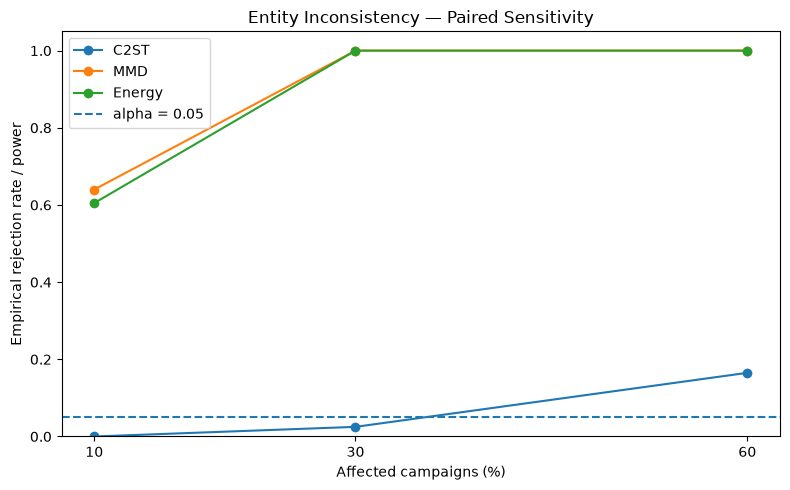

In [52]:
# sensitivity curve
import matplotlib.pyplot as plt


plt.figure(
    figsize=(8, 5)
)

for metric in [
    "C2ST",
    "MMD",
    "Energy"
]:

    subset = (
        entity_power_summary[
            entity_power_summary[
                "metric"
            ] == metric
        ]
        .sort_values(
            "severity"
        )
    )

    plt.plot(
        subset["severity"] * 100,
        subset["power"],
        marker="o",
        label=metric
    )


plt.axhline(
    ALPHA,
    linestyle="--",
    label="alpha = 0.05"
)

plt.xlabel(
    "Affected campaigns (%)"
)

plt.ylabel(
    "Empirical rejection rate / power"
)

plt.title(
    "Entity Inconsistency — "
    "Paired Sensitivity"
)

plt.ylim(
    0,
    1.05
)

plt.xticks(
    [
        10,
        30,
        60
    ]
)

plt.legend()

plt.tight_layout()

plt.show()


In [53]:
# for tyoe 1 error - clean vs independent clean

from src.metrics import (
    c2st,
    mmd_permutation_test,
    energy_permutation_test
)

In [54]:
NULL_REPS = 200

null_rng = np.random.default_rng(
    BASE_SEED
)

clean_embedding_df = (
    entity_embeddings[
        "clean"
    ]
)

clean_X = (
    clean_embedding_df[
        EMBEDDING_FEATURES
    ]
    .to_numpy()
)

null_records = []


for rep in range(
    NULL_REPS
):

    selected = null_rng.choice(
        len(clean_X),
        size=200,
        replace=False
    )

    P = clean_X[
        selected[:100]
    ]

    Q = clean_X[
        selected[100:]
    ]

    seed = (
        BASE_SEED + rep
    )

    # C2ST
    result = c2st(
        P,
        Q,
        test_size=0.5,
        seed=seed,
        alpha=ALPHA
    )

    stat, p, reject = (
        extract_metric_result(
            result,
            "C2ST"
        )
    )

    null_records.append({
        "repetition": rep,
        "metric": "C2ST",
        "statistic": stat,
        "p_value": p,
        "reject": reject
    })

    # MMD
    result = (
    mmd_paired_permutation_test(
    P,
    Q,
    sigma=SEMANTIC_MMD_SIGMA,
    n_permutations=N_PERMUTATIONS,
    seed=metric_seed,
    alpha=ALPHA
        )
    )



    stat, p, reject = (
        extract_metric_result(
            result,
            "MMD"
        )
    )

    null_records.append({
        "repetition": rep,
        "metric": "MMD",
        "statistic": stat,
        "p_value": p,
        "reject": reject
    })

    # Energy
    result = (
    energy_paired_permutation_test(
    P,
    Q,
    n_permutations=N_PERMUTATIONS,
    seed=metric_seed,
    alpha=ALPHA
        )
    )

    stat, p, reject = (
        extract_metric_result(
            result,
            "Energy"
        )
    )

    null_records.append({
        "repetition": rep,
        "metric": "Energy",
        "statistic": stat,
        "p_value": p,
        "reject": reject
    })


entity_null_results = pd.DataFrame(
    null_records
)

In [55]:
entity_null_summary = (
    entity_null_results
    .groupby(
        "metric"
    )
    .agg(
        rejections=(
            "reject",
            "sum"
        ),

        type_I_error=(
            "reject",
            "mean"
        ),

        mean_p_value=(
            "p_value",
            "mean"
        )
    )
    .reset_index()
)

display(
    entity_null_summary
)

,metric,rejections,type_I_error,mean_p_value
0,C2ST,7,0.035,0.549234
1,Energy,11,0.055,0.505050
2,MMD,11,0.055,0.505743


In [56]:
entity_null_results.to_csv(
    "../results/"
    "entity_inconsistency_clean_null.csv",
    index=False
)

entity_power_summary.to_csv(
    "../results/"
    "entity_inconsistency_power_summary.csv",
    index=False
)

MMD and Energy Distance detect Entity Inconsistency with significantly higher sensitivity than C2ST, while all three tests maintain well-calibrated behavior under the null.

### Sensitivity Curve

At 10% affected campaigns, MMD achieves a power of 0.640 and Energy Distance reaches 0.605. This means that even when a sample of 100 campaigns contains, on average, only about 10 defective campaigns, both metrics successfully detect the distributional change 60–64% of the time.

By 30% prevalence, both metrics reach:

$$ \text{power} = 1.00 $$

and remain at 1.00 at 60% prevalence. This indicates that, under this semantic representation, once approximately 30 campaigns are affected within a sample of 100, the distributional shift becomes strong enough to be detected nearly 100% of the time by MMD and Energy Distance under this configuration.

The representation preserves sufficient information about Entity Inconsistency; however, the linear logistic regression-based C2ST struggles to translate this subtle semantic shift into a clear classification boundary.

This is conceptually similar to the variance shift observed in Week 3: it is not enough to ask whether "the defect exists." The detection outcome inherently depends on the combined tuple:

$$ \text{defect} \times \text{representation} \times \text{metric/test architecture} $$

This confirms that the representation itself is not the primary bottleneck.

*Note: In our implementation, we use U-statistic estimators. These estimators can produce slightly negative empirical values in finite samples, even though the underlying population quantities are non-negative.*

### Entity Inconsistency — Paired Sensitivity Results

Entity Inconsistency produced markedly different detection behavior across
the three metrics despite all tests receiving exactly the same
384-dimensional campaign embeddings.

MMD and Energy Distance were substantially more sensitive to the injected
defect. At 10% defect prevalence, empirical power was 0.640 for MMD and
0.605 for Energy Distance. When prevalence increased to 30%, both metrics
reached a power of 1.000 and remained fully saturated at the 60% severity
level.

C2ST showed a substantially different response. Its empirical rejection
rates were 0.000, 0.025, and 0.165 at 10%, 30%, and 60% defect prevalence,
respectively. Mean classification accuracy increased only from 0.503 at
10% to 0.527 at 60%, indicating that the linear logistic-regression
classifier had difficulty separating clean and defective campaign
embeddings.

This contrast is important because all three methods operated on the same
semantic representation. Consequently, the weak C2ST result cannot be
interpreted simply as a failure of the embedding representation to retain
the Entity Inconsistency signal. MMD and Energy Distance demonstrate that
a detectable distributional change is present in the representation.
Instead, the result suggests that the particular classifier used by C2ST
is relatively insensitive to the form of distributional change produced
by this defect.

The clean-vs-clean null experiment showed Type I error rates of 0.035 for
C2ST and 0.055 for both MMD and Energy Distance, all close to the nominal
alpha level of 0.05. The high power observed for MMD and Energy Distance
therefore does not appear to result from uncontrolled false-positive
behavior.

Across the 200 repetitions, samples contained an average of 10.02, 29.90,
and 59.80 affected campaigns at the nominal 10%, 30%, and 60% severity
levels. This confirms that the prevalence-based severity design behaved
as intended while retaining natural sampling variability.

Overall, Entity Inconsistency reveals a clear metric-specific sensitivity
difference: the general semantic representation preserves sufficient
information for kernel- and distance-based two-sample tests to detect the
defect, while the linear C2ST remains largely insensitive except at the
highest prevalence level.

In [57]:
SEVERITIES = [
    0.10,
    0.30,
    0.60
]


entity_result_candidates = []


for name, obj in list(
    globals().items()
):

    if not isinstance(
        obj,
        dict
    ):
        continue

    if not all(
        severity in obj
        for severity in SEVERITIES
    ):
        continue

    try:

        valid = all(
            isinstance(
                obj[severity],
                dict
            )
            and
            "audit"
            in obj[severity]
            and
            "campaign_id"
            in obj[severity][
                "audit"
            ].columns

            for severity
            in SEVERITIES
        )

    except Exception:

        valid = False


    if valid:

        entity_result_candidates.append(
            name
        )


print(
    "Possible Entity result dictionaries:"
)

print(
    entity_result_candidates
)

Possible Entity result dictionaries:
['entity_inconsistency_results']


In [58]:
entity_results_for_export = (
    entity_inconsistency_results
)

In [59]:
for severity in SEVERITIES:

    audit = (
        entity_results_for_export[
            severity
        ]["audit"]
    )

    print(
        f"{severity:.0%}: "
        f"{len(audit)} affected campaigns"
    )

    print(
        "unique IDs:",
        audit[
            "campaign_id"
        ].nunique()
    )

10%: 30 affected campaigns
unique IDs: 30
30%: 90 affected campaigns
unique IDs: 90
60%: 180 affected campaigns
unique IDs: 180


In [60]:
from src.io_utils import (
    save_affected_ids_by_severity
)


entity_affected_ids = {
    severity:
        entity_results_for_export[
            severity
        ]["audit"][
            "campaign_id"
        ].to_numpy()

    for severity in SEVERITIES
}


entity_affected_df = (
    save_affected_ids_by_severity(
        entity_affected_ids,

        "../data/processed/"
        "entity_inconsistency_"
        "affected_campaign_ids.csv",

        id_column="campaign_id"
    )
)


display(
    entity_affected_df
    .groupby("severity")
    .size()
)

severity
0.1     30
0.3     90
0.6    180
dtype: int64

In [61]:
ids_10 = set(
    entity_affected_df.loc[
        entity_affected_df[
            "severity"
        ] == 0.10,
        "campaign_id"
    ]
)

ids_30 = set(
    entity_affected_df.loc[
        entity_affected_df[
            "severity"
        ] == 0.30,
        "campaign_id"
    ]
)

ids_60 = set(
    entity_affected_df.loc[
        entity_affected_df[
            "severity"
        ] == 0.60,
        "campaign_id"
    ]
)


assert ids_10.issubset(
    ids_30
)

assert ids_30.issubset(
    ids_60
)


print(
    "Nested Entity severity "
    "validation passed."
)

Nested Entity severity validation passed.


In [62]:
CID = "C0596"

ids = entity_serialized["clean"]["campaign_id"].to_numpy()
pos = np.flatnonzero(ids == CID)[0]

print("Campaign:", CID)
print("Row position:", pos)

Campaign: C0596
Row position: 180


In [64]:
saved = {
    "clean": np.load("../data/processed/entity_embeddings_clean.npy"),
    0.30: np.load("../data/processed/entity_embeddings_30pct.npy"),
    0.60: np.load("../data/processed/entity_embeddings_60pct.npy")
}

for condition in ["clean", 0.30, 0.60]:
    current = entity_embedding_arrays[condition][pos]
    stored = saved[condition][pos]
    print(
        condition,
        "| current-vs-saved =", f"{np.linalg.norm(current - stored):.12e}"
    )

clean | current-vs-saved = 1.120102083814e-01
0.3 | current-vs-saved = 1.140101643272e-01
0.6 | current-vs-saved = 1.140101643272e-01


In [65]:
for severity in [0.30, 0.60]:
    current_d = np.linalg.norm(
        entity_embedding_arrays[severity][pos] -
        entity_embedding_arrays["clean"][pos]
    )

    saved_d = np.linalg.norm(
        saved[severity][pos] -
        saved["clean"][pos]
    )

    print(
        f"{severity:.0%}",
        "| current clean→def =", f"{current_d:.12e}",
        "| saved clean→def =", f"{saved_d:.12e}"
    )

30% | current clean→def = 2.426453886776e-02 | saved clean→def = 0.000000000000e+00
60% | current clean→def = 2.426453886776e-02 | saved clean→def = 0.000000000000e+00


In [66]:
cols = [
    "campaign_id",
    "target_message_id",
    "target_message_order",
    "canonical_name",
    "inconsistent_name",
    "original_text",
    "defective_text"
]

audit_30 = entity_inconsistency_results[0.30]["audit"]
audit_60 = entity_inconsistency_results[0.60]["audit"]

display(audit_30.loc[audit_30["campaign_id"] == CID, cols])
display(audit_60.loc[audit_60["campaign_id"] == CID, cols])

,campaign_id,target_message_id,target_message_order,canonical_name,inconsistent_name,original_text,defective_text
56,C0596,C0596_M09,9,Adrian Foster,Adrian Torres,"I can provide more information if needed, Adri...","I can provide more information if needed, Adri..."


,campaign_id,target_message_id,target_message_order,canonical_name,inconsistent_name,original_text,defective_text
109,C0596,C0596_M09,9,Adrian Foster,Adrian Torres,"I can provide more information if needed, Adri...","I can provide more information if needed, Adri..."


In [67]:
r30 = audit_30.loc[audit_30["campaign_id"] == CID].iloc[0]
r60 = audit_60.loc[audit_60["campaign_id"] == CID].iloc[0]

print("Original != defective:", r30["original_text"] != r30["defective_text"])
print("Same defective text at 30/60:", r30["defective_text"] == r60["defective_text"])
print("Target:", r30["target_message_id"])
print("Name:", r30["canonical_name"], "→", r30["inconsistent_name"])

Original != defective: True
Same defective text at 30/60: True
Target: C0596_M09
Name: Adrian Foster → Adrian Torres


In [68]:
target_id = r30["target_message_id"]

clean_msg = clean_campaigns_eval.loc[
    clean_campaigns_eval["message_id"] == target_id,
    ["message_id", "text"]
]

def_msg = entity_inconsistency_results[0.30]["defective"].loc[
    entity_inconsistency_results[0.30]["defective"]["message_id"] == target_id,
    ["message_id", "text"]
]

display(clean_msg)
display(def_msg)

print(
    "Actual message text changed:",
    clean_msg.iloc[0]["text"] != def_msg.iloc[0]["text"]
)

,message_id,text
1255,C0596_M09,"I can provide more information if needed, Adri..."


,message_id,text
1255,C0596_M09,"I can provide more information if needed, Adri..."


Actual message text changed: True


In [69]:
clean_ser = entity_serialized["clean"].loc[
    entity_serialized["clean"]["campaign_id"] == CID,
    "serialized_text"
].iloc[0]

def_ser = entity_serialized[0.30].loc[
    entity_serialized[0.30]["campaign_id"] == CID,
    "serialized_text"
].iloc[0]

print("Serialized text changed:", clean_ser != def_ser)
print("Clean chars:", len(clean_ser))
print("Defective chars:", len(def_ser))

Serialized text changed: True
Clean chars: 955
Defective chars: 955


In [70]:
import difflib

print("\n".join(
    difflib.unified_diff(
        clean_ser.splitlines(),
        def_ser.splitlines(),
        fromfile="clean",
        tofile="defective",
        lineterm=""
    )
))

--- clean
+++ defective
@@ -6,4 +6,4 @@
 [MESSAGE 6] [CHANNEL=EMAIL] [CLIENT->ADVISOR] Thanks. I will review the remaining information.
 [MESSAGE 7] [CHANNEL=WHATSAPP] [ADVISOR->CLIENT] I can provide more information if needed, Adrian Foster.
 [MESSAGE 8] [CHANNEL=WHATSAPP] [CLIENT->ADVISOR] Thanks, that answers my question.
-[MESSAGE 9] [CHANNEL=SMS] [ADVISOR->CLIENT] I can provide more information if needed, Adrian Foster.
+[MESSAGE 9] [CHANNEL=SMS] [ADVISOR->CLIENT] I can provide more information if needed, Adrian Torres.


In [71]:
clean_tokens = embedding_model.tokenizer(
    clean_ser, add_special_tokens=True, truncation=False
)["input_ids"]

def_tokens = embedding_model.tokenizer(
    def_ser, add_special_tokens=True, truncation=False
)["input_ids"]

print("Same token IDs:", clean_tokens == def_tokens)
print("Clean tokens:", len(clean_tokens))
print("Defective tokens:", len(def_tokens))

Same token IDs: False
Clean tokens: 259
Defective tokens: 259


In [72]:
clean_chunks = split_campaign_into_chunks(clean_ser, embedding_model)
def_chunks = split_campaign_into_chunks(def_ser, embedding_model)

print("Clean chunks:", len(clean_chunks))
print("Defective chunks:", len(def_chunks))

Clean chunks: 2
Defective chunks: 2


In [73]:
for i, (c, d) in enumerate(zip(clean_chunks, def_chunks), start=1):
    c_ids = embedding_model.tokenizer(
        c, add_special_tokens=True, truncation=False
    )["input_ids"]

    d_ids = embedding_model.tokenizer(
        d, add_special_tokens=True, truncation=False
    )["input_ids"]

    print(
        f"Chunk {i}:",
        "clean tokens =", len(c_ids),
        "| defective tokens =", len(d_ids),
        "| same IDs =", c_ids == d_ids
    )

Chunk 1: clean tokens = 233 | defective tokens = 233 | same IDs = True
Chunk 2: clean tokens = 28 | defective tokens = 28 | same IDs = False


In [74]:
clean_chunk_emb = embedding_model.encode(
    clean_chunks,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=False
)

def_chunk_emb = embedding_model.encode(
    def_chunks,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=False
)

for i in range(len(clean_chunks)):
    d = np.linalg.norm(clean_chunk_emb[i] - def_chunk_emb[i])
    print(f"Chunk {i + 1} embedding distance: {d:.12e}")

Chunk 1 embedding distance: 0.000000000000e+00
Chunk 2 embedding distance: 2.317921966314e-01


In [75]:
one_clean = pd.DataFrame({
    "campaign_id": [CID],
    "serialized_text": [clean_ser]
})

one_def = pd.DataFrame({
    "campaign_id": [CID],
    "serialized_text": [def_ser]
})

X_clean, _ = encode_serialized_campaigns(
    one_clean, embedding_model, batch_size=64
)

X_def, _ = encode_serialized_campaigns(
    one_def, embedding_model, batch_size=64
)

print(
    "Recomputed final campaign distance:",
    f"{np.linalg.norm(X_def[0] - X_clean[0]):.12e}"
)

Campaigns: 1
Chunks to encode: 2


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Campaigns: 1
Chunks to encode: 2


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Recomputed final campaign distance: 2.426453886776e-02


In [76]:
print(
    "Recomputed clean vs current clean:",
    f"{np.linalg.norm(X_clean[0] - entity_embedding_arrays['clean'][pos]):.12e}"
)

print(
    "Recomputed def vs current def:",
    f"{np.linalg.norm(X_def[0] - entity_embedding_arrays[0.30][pos]):.12e}"
)

print(
    "Recomputed clean vs saved clean:",
    f"{np.linalg.norm(X_clean[0] - saved['clean'][pos]):.12e}"
)

print(
    "Recomputed def vs saved def:",
    f"{np.linalg.norm(X_def[0] - saved[0.30][pos]):.12e}"
)

Recomputed clean vs current clean: 0.000000000000e+00
Recomputed def vs current def: 0.000000000000e+00
Recomputed clean vs saved clean: 1.120102083814e-01
Recomputed def vs saved def: 1.140101643272e-01


In [77]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_DIR = Path("../data/processed")

saved_entity = {
    "clean": np.load(DATA_DIR / "entity_embeddings_clean.npy"),
    0.10: np.load(DATA_DIR / "entity_embeddings_10pct.npy"),
    0.30: np.load(DATA_DIR / "entity_embeddings_30pct.npy"),
    0.60: np.load(DATA_DIR / "entity_embeddings_60pct.npy")
}

mismatch_records = []

for condition in ["clean", 0.10, 0.30, 0.60]:
    current = entity_embedding_arrays[condition]
    saved = saved_entity[condition]

    row_distances = np.linalg.norm(current - saved, axis=1)

    mismatch_records.append({
        "condition": condition,
        "n_rows": len(row_distances),
        "mismatched_rows": int((row_distances > 1e-8).sum()),
        "mean_current_vs_saved": row_distances.mean(),
        "median_current_vs_saved": np.median(row_distances),
        "max_current_vs_saved": row_distances.max()
    })

entity_artifact_mismatch_summary = pd.DataFrame(mismatch_records)
display(entity_artifact_mismatch_summary)

,condition,n_rows,mismatched_rows,mean_current_vs_saved,median_current_vs_saved,max_current_vs_saved
0,clean,300,300,0.003409,4.165782e-08,0.159221
1,0.1,300,300,0.003409,4.437153e-08,0.159221
2,0.3,300,300,0.003416,4.324456e-08,0.159221
3,0.6,300,300,0.003420,4.528288e-08,0.159221


In [78]:
RESULTS_DIR = Path("../results/week7")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

entity_artifact_mismatch_summary.to_csv(
    RESULTS_DIR / "entity_embedding_artifact_mismatch_summary.csv",
    index=False
)

print("Mismatch diagnostic saved.")

Mismatch diagnostic saved.


In [79]:
c0596_diagnostic = pd.DataFrame([{
    "campaign_id": "C0596",
    "severity": 0.30,
    "current_clean_to_defective_distance": np.linalg.norm(
        entity_embedding_arrays[0.30][pos] -
        entity_embedding_arrays["clean"][pos]
    ),
    "saved_clean_to_defective_distance": np.linalg.norm(
        saved_entity[0.30][pos] -
        saved_entity["clean"][pos]
    ),
    "chunk_2_embedding_distance": np.linalg.norm(
        clean_chunk_emb[1] - def_chunk_emb[1]
    ),
    "recomputed_campaign_distance": np.linalg.norm(
        X_def[0] - X_clean[0]
    )
}])

display(c0596_diagnostic)

c0596_diagnostic.to_csv(
    RESULTS_DIR / "entity_C0596_artifact_diagnostic.csv",
    index=False
)

,campaign_id,severity,current_clean_to_defective_distance,saved_clean_to_defective_distance,chunk_2_embedding_distance,recomputed_campaign_distance
0,C0596,0.3,0.024265,0.0,0.231792,0.024265


In [80]:
import shutil

BACKUP_DIR = DATA_DIR / "archive" / "entity_embeddings_stale_pre_week7"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

files = [
    "entity_embeddings_clean.npy",
    "entity_embeddings_10pct.npy",
    "entity_embeddings_30pct.npy",
    "entity_embeddings_60pct.npy"
]

for filename in files:
    shutil.copy2(
        DATA_DIR / filename,
        BACKUP_DIR / filename
    )

print("Old Entity embedding files backed up to:")
print(BACKUP_DIR)

Old Entity embedding files backed up to:
../data/processed/archive/entity_embeddings_stale_pre_week7


In [81]:
import importlib
import src.io_utils as io_utils

importlib.reload(io_utils)

from src.io_utils import save_embedding_conditions

In [82]:
saved_paths = save_embedding_conditions(
    entity_embedding_arrays,
    DATA_DIR,
    prefix="entity"
)

for condition, path in saved_paths.items():
    print(condition, "->", path.name)

clean -> entity_embeddings_clean.npy
0.1 -> entity_embeddings_10pct.npy
0.3 -> entity_embeddings_30pct.npy
0.6 -> entity_embeddings_60pct.npy


In [83]:
from src.io_utils import load_embedding_conditions

entity_reloaded = load_embedding_conditions(
    DATA_DIR,
    prefix="entity"
)

for condition in ["clean", 0.10, 0.30, 0.60]:
    diff = np.linalg.norm(
        entity_embedding_arrays[condition] -
        entity_reloaded[condition],
        axis=1
    )

    print(
        condition,
        "| mismatched rows =", (diff > 1e-8).sum(),
        "| max diff =", f"{diff.max():.12e}"
    )

clean | mismatched rows = 0 | max diff = 0.000000000000e+00
0.1 | mismatched rows = 0 | max diff = 0.000000000000e+00
0.3 | mismatched rows = 0 | max diff = 0.000000000000e+00
0.6 | mismatched rows = 0 | max diff = 0.000000000000e+00


In [84]:
for severity in [0.30, 0.60]:
    d = np.linalg.norm(
        entity_reloaded[severity][pos] -
        entity_reloaded["clean"][pos]
    )

    print(
        f"{severity:.0%}",
        "| C0596 distance =",
        f"{d:.12e}"
    )

30% | C0596 distance = 2.426453886776e-02
60% | C0596 distance = 2.426453886776e-02


In [85]:
ids = entity_serialized["clean"]["campaign_id"].to_numpy()

for severity in [0.10, 0.30, 0.60]:
    distances = np.linalg.norm(
        entity_reloaded[severity] -
        entity_reloaded["clean"],
        axis=1
    )

    changed_ids = set(ids[distances > 1e-8])
    affected_ids = set(
        entity_inconsistency_results[severity]["audit"]["campaign_id"]
    )

    print(
        f"{severity:.0%}",
        "| changed =", len(changed_ids),
        "| affected =", len(affected_ids),
        "| exact match =", changed_ids == affected_ids
    )

    assert changed_ids == affected_ids

10% | changed = 30 | affected = 30 | exact match = True
30% | changed = 90 | affected = 90 | exact match = True
60% | changed = 180 | affected = 180 | exact match = True


In [86]:
summary_records = []

for severity in [0.10, 0.30, 0.60]:
    distances = np.linalg.norm(
        entity_reloaded[severity] -
        entity_reloaded["clean"],
        axis=1
    )

    affected_ids = set(
        entity_inconsistency_results[severity]["audit"]["campaign_id"]
    )

    affected_mask = np.array([
        campaign_id in affected_ids
        for campaign_id in ids
    ])

    affected = distances[affected_mask]

    summary_records.append({
        "severity": severity,
        "affected_campaigns": affected_mask.sum(),
        "mean_change_all": distances.mean(),
        "mean_change_affected": affected.mean(),
        "median_change_affected": np.median(affected),
        "zero_embedding_change": int((affected <= 1e-8).sum()),
        "max_change": affected.max()
    })

entity_embedding_change_corrected = pd.DataFrame(summary_records)
display(entity_embedding_change_corrected)

,severity,affected_campaigns,mean_change_all,mean_change_affected,median_change_affected,zero_embedding_change,max_change
0,0.1,30,0.006340,0.063403,0.062811,0,0.122291
1,0.3,90,0.017908,0.059693,0.054587,0,0.220437
2,0.6,180,0.035077,0.058461,0.054144,0,0.220437


In [87]:
entity_embedding_change_corrected.to_csv(
    RESULTS_DIR / "entity_embedding_change_corrected.csv",
    index=False
)

print("Corrected Entity embedding summary saved.")

Corrected Entity embedding summary saved.


### Entity Embedding Artifact Mismatch

During the Week 7 embedding-distance analysis, campaign `C0596` appeared
to have zero clean-to-defective embedding displacement at both 30% and
60% defect prevalence.

This was unexpected because the original Entity Inconsistency notebook
had previously verified that every affected campaign produced a non-zero
embedding change. Since the severity sets are nested, the same campaign
appeared as a zero-displacement case at both prevalence levels.

We therefore traced `C0596` through the full representation pipeline.

The injected defect was confirmed to be valid: the target message changed
from `Adrian Foster` to `Adrian Torres`, and the clean and defective
serialized campaigns were different. The tokenizer also produced different
token IDs, so the modification was not removed during tokenization.

`C0596` was split into two chunks because its serialized campaign exceeded
the model sequence-length limit. The first chunk was identical between the
clean and defective versions, while the second chunk contained the modified
entity name. The second-chunk embeddings differed substantially
(Euclidean distance ≈ 0.232).

After token-weighted chunk aggregation and final L2 normalization, the
clean and defective campaign embeddings still differed by approximately
0.0243. Recomputing the campaign representation produced exactly the same
vectors as the current in-memory embeddings.

The discrepancy was therefore not caused by the defect injection,
tokenizer, encoder, chunking procedure, or campaign-level aggregation.
Instead, the `.npy` embedding files previously stored in `data/processed`
did not match the embedding arrays produced by the current validated
pipeline. For `C0596`, the old saved files incorrectly produced zero
clean-to-defective displacement.

To preserve the history of the experiment, the previous `.npy` files were
archived rather than deleted. The validated in-memory embedding arrays were
then saved again using the standardized embedding I/O functions, reloaded
from disk, and checked against the original arrays.

After replacement, every saved embedding row matched its corresponding
in-memory vector, and the affected campaign IDs again matched the set of
campaigns with non-zero embedding displacement at all three severity
levels.

This issue was therefore classified as an artifact-persistence mismatch,
not a representation-level blind spot. No defect definitions, model
parameters, embeddings, or metric procedures were changed. Only the stale
stored embedding artifacts were replaced with the already validated
embeddings produced by the original pipeline.

**Impact on previous results.**  
The original C2ST, MMD, and Energy Distance experiments were run directly
from the validated in-memory embedding matrices, so their previously saved
power results do not need to be recomputed. Only analyses that later loaded
the stale `.npy` files from disk, such as the initial Week 7 embedding-distance
analysis, must be rerun after correcting the stored artifacts.